#**DATA SCIENCE TRACK**

#**CAPSTONE PROJECT FOR GROUP 17**

## **IMPORTING LIBRARIES**
This section imports all the necessary Python libraries used for data manipulation, visualization, and machine learning. Pandas and NumPy are used for data handling, Matplotlib and Seaborn for visualization, and Scikit-learn for model building and evaluation.

In [1]:
# Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## **LOADING THE DATASET**
The dataset is loaded into a Pandas DataFrame to allow easy inspection, cleaning, and analysis of the housing data.

In [2]:
# Loading the csv file
df = pd.read_csv('Bengaluru_House_Data.csv')
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


## **Data Understanding & Exploration**
### **Inspect dataset Structure and data types**
Initial inspection is performed to understand the structure of the dataset, including the number of rows and columns, data types, and presence of missing values.

In [3]:
# Displaying headers
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [4]:
# Displaying the structure of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [5]:
# Descriptive statistics for numerical features
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [6]:
# Inspecting the number of rows and columns
df.shape

(13320, 9)

### **Identifying missing values and inconsistencies**
Missing values are identified to determine which columns require cleaning or imputation before further analysis and modeling.

In [8]:
df.isna().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

<Axes: title={'center': 'Columns with missing values'}>

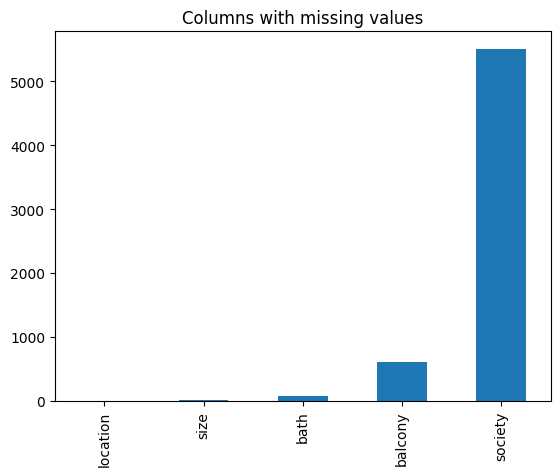

In [9]:
# Inspecting the magnitude of the missing values
missing = df[['society', 'balcony', 'bath', 'size', 'location']].isna().sum()
missing.sort_values(inplace=True)
plt.title('Columns with missing values')
missing.plot.bar()

### **Understanding distribution of target variable**
This step examines the distribution of the target variable (house price) to understand its spread, central tendency, and skewness. This helps identify outliers and informs whether data transformation or special handling is required before modeling.


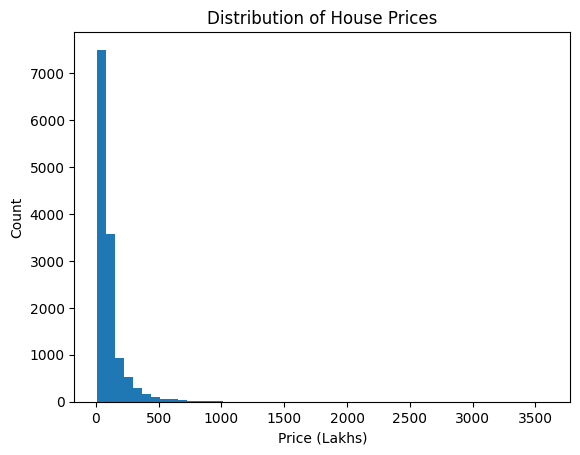

In [10]:
# Target Variable Distribution(Price)
plt.figure()
plt.hist(df['price'], bins=50)
plt.xlabel("Price (Lakhs)")
plt.ylabel("Count")
plt.title("Distribution of House Prices")
plt.show()

Insight: The histogram was used to visualize the distribution of house prices. This helps identify whether prices are normally distributed or skewed, and highlights the presence of extreme values.
We can see that our Prices are right-skewed and there are presence of extreme values (outlier).

### **Analyze relationships between features and price**

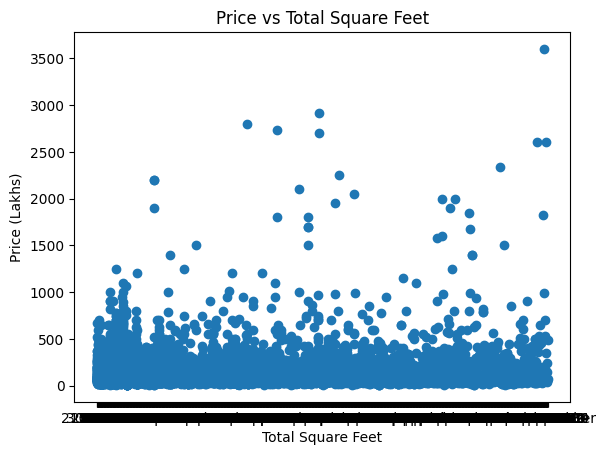

In [11]:
# Price vs Total Square Feet
plt.figure()
plt.scatter(df['total_sqft'], df['price'])
plt.xlabel("Total Square Feet")
plt.ylabel("Price (Lakhs)")
plt.title("Price vs Total Square Feet")
plt.show()

Insight: The scatter plot is used to visualize how house prices vary with total square footage. The pattern suggests that larger houses tend to be more expensive, though some variability exists due to location and other factors.

In [12]:
# Extract BHK from size and convert to a numerical value
df['bhk'] = df['size'].str.extract(r'(\d+)').astype(float)
df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07,2.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00,4.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00,3.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00,3.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00,2.0


Insight: Since the size feature is stored as text, the BHK (number of bedrooms) is extracted and converted into a numerical format, allowing it to be used as a quantitative feature in the regression model.


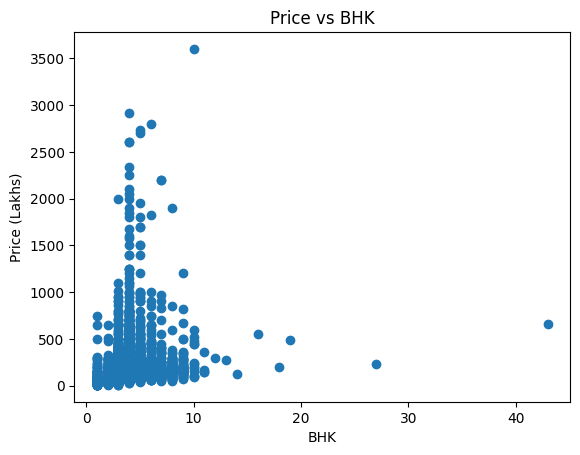

In [13]:
# Prive vs BHK
plt.figure()
plt.scatter(df['bhk'], df['price'])
plt.xlabel("BHK")
plt.ylabel("Price (Lakhs)")
plt.title("Price vs BHK")
plt.show()

Insight: The scatter plot is used to visualize the distribution of house prices across different BHK values, highlighting both trends and price variability.

The results show that houses with more bedrooms generally have higher prices, but can still be affected by the location.

## **Data Cleaning & Pre-processing**
### **Convert non-numeric values in total_sqft**
The total_sqft column contains non-numeric values such as ranges and text. These values are converted into numerical format to make the feature usable for mathematical operations and modeling.
-  Reduce high cardinality in
-  Remove extreme outliers logically
-  Encode categorical variables


In [14]:
# Converting total_sqft to numeric values
def convert_sqft_to_num(x):
    try:
        if '-' in x:
            values = x.split('-')
            return (float(values[0]) + float(values[1])) / 2
        else:
            return float(x)
    except:
        return None

In [15]:
# Applying the conversion to the total_sqft column
df['total_sqft'] = df['total_sqft'].apply(convert_sqft_to_num)

In [16]:
# Checking the total_sqft column
df.iloc[872: 888]

,area_type,availability,location,size,society,total_sqft,bath,balcony,price,bhk
872,Super built-up Area,Ready To Move,Singapura Village,2 BHK,NaN,NaN,2.0,NaN,45.000,2.0
873,Super built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,GrrvaGr,1140.0,2.0,1.0,49.390,2.0
874,Super built-up Area,Ready To Move,Battarahalli,2 BHK,Sancy L,1300.0,2.0,1.0,50.000,2.0
875,Super built-up Area,Ready To Move,Hosa Road,3 BHK,NaN,1652.0,3.0,2.0,85.000,3.0
876,Super built-up Area,Ready To Move,Thigalarapalya,3 BHK,Prtanha,2072.0,4.0,2.0,142.000,3.0
877,Built-up Area,Ready To Move,Arekere,3 BHK,NaN,1740.0,2.0,NaN,95.000,3.0
878,Super built-up Area,Ready To Move,Electronic City,3 BHK,GMown E,1360.0,2.0,1.0,71.000,3.0
879,Super built-up Area,Ready To Move,Hosur Road,3 BHK,Sueneu,1145.0,2.0,2.0,60.000,3.0
880,Built-up Area,Ready To Move,Uttarahalli,3 BHK,Laihai,1540.0,2.0,0.0,40.000,3.0
881,Super built-up Area,Ready To Move,Sarjapur Road,2 BHK,Adeatlm,1278.0,2.0,2.0,95.000,2.0


Insight: We can see that we have successfully converted the values in the total square foot column to numerical values

### **Handling Missing Values appropriately**

In [17]:
# Drop rows with critical missing values in total_sqft, bhk and bath colunm.
df = df.dropna(subset=['total_sqft', 'bhk', 'bath'])

Insight: Rows with missing critical values are removed to ensure data consistency and prevent errors during model training.

In [18]:
# Drop society columns because of 41% missing values and very high cardinality.
df = df.drop(columns=['society'])

In [19]:
# Checking to see if the above codes have been implemented
df.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056.0,2.0,1.0,39.07,2.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600.0,5.0,3.0,120.00,4.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2.0,3.0,62.00,3.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521.0,3.0,1.0,95.00,3.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200.0,2.0,1.0,51.00,2.0


### **Reduction of high cardinality in location**

In [20]:
len(df['location'].unique())

1299

In [21]:
df['location'] = df['location'].astype(str).apply(lambda x: x.strip())
location_stats = df['location'].value_counts()

locations_less_than_10 = location_stats[location_stats <= 10]
df['location'] = df['location'].apply(
    lambda x: 'other' if x in locations_less_than_10 else x
)

Insight: Locations with very few data points are grouped into an "other" category to reduce high cardinality, prevent overfitting, and improve model generalization.

In [22]:
len(df['location'].unique())

241

### **Feature Engineering: Price per Sqft**

In [23]:
# We create price_per_sqft so we can standardize our prices
# price_per_sqft stabilizes variance

df['price_per_sqft']= (df['price'] * 100000) / df['total_sqft']

Insight: A new feature, price per square foot, is created to normalize house prices and allow better comparison across properties of different sizes.

In [24]:
df.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,bhk,price_per_sqft
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056.0,2.0,1.0,39.07,2.0,3699.810606
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600.0,5.0,3.0,120.00,4.0,4615.384615
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440.0,2.0,3.0,62.00,3.0,4305.555556
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521.0,3.0,1.0,95.00,3.0,6245.890861
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200.0,2.0,1.0,51.00,2.0,4250.000000


In [25]:
# inspect extreme values
df['price_per_sqft'].describe()

count    1.320100e+04
mean     7.920566e+03
std      1.067231e+05
min      2.678298e+02
25%      4.267782e+03
50%      5.438066e+03
75%      7.317073e+03
max      1.200000e+07
Name: price_per_sqft, dtype: float64

### **Outlier Removal**
Properties with unrealistically small square footage per bedroom are removed, as they represent data anomalies that can negatively affect model performance.

In [26]:
df = df[df['total_sqft']/ df['bhk'] >= 300]
df.shape

(12457, 10)

In [27]:
# Calculating Mean and Standard Deviation
mean_pps = df['price_per_sqft'].mean()
std_pps = df['price_per_sqft'].std()
print(mean_pps, std_pps)

6308.427888035141 4167.968413078405


Insight: The mean and standard deviation are calculated to understand the normal range of price per square foot and to help identify unusually high or low values that may be outliers.

In [28]:
# Defining Lower and Upper Bounds
lower_limit = mean_pps - std_pps
upper_limit = mean_pps + std_pps

In [29]:
# Filtering the data (Removing Outliers)
df = df[
    (df['price_per_sqft'] >= lower_limit) &
    (df['price_per_sqft'] <= upper_limit)
    ]

In [30]:
print('Data shape after outlier removal :', df.shape)

Data shape after outlier removal : (11295, 10)


Text(0, 0.5, 'Count')

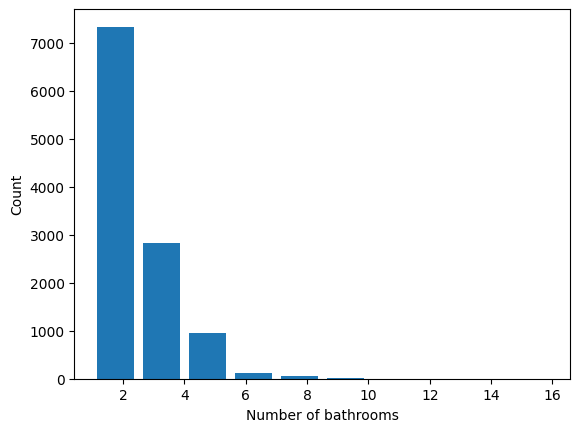

In [31]:
plt.hist(df.bath, rwidth= 0.8)
plt.xlabel('Number of bathrooms')
plt.ylabel('Count')

In [32]:
df = df[df.bath < df.bhk+2]
df.shape

(11199, 10)

##**Encoding Categorical Variables**

Categorical features such as location are converted into numerical format using one-hot encoding so they can be used in the machine learning model.

###**Encoding location feature using one hot encoding**

In [33]:
# Using One-Hot Encoding to Encode Location
dummies = pd.get_dummies(df['location'], drop_first=True)
dummies = dummies.astype(int)
df = pd.concat([df, dummies], axis=1)
df.drop('location', axis=1, inplace=True)

The location feature is a categorical variable with multiple categories. One-hot encoding is used to convert each location into a numerical column. The drop_first=True option is applied to avoid multicollinearity, and the encoded columns are added to the dataset while the original location column is removed.

In [34]:
df.head(5)

,area_type,availability,size,total_sqft,bath,balcony,price,bhk,price_per_sqft,1st Phase JP Nagar,...,Vishveshwarya Layout,Vishwapriya Layout,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur,other
0,Super built-up Area,19-Dec,2 BHK,1056.0,2.0,1.0,39.07,2.0,3699.810606,0,...,0,0,0,0,0,0,0,0,0,0
1,Plot Area,Ready To Move,4 Bedroom,2600.0,5.0,3.0,120.00,4.0,4615.384615,0,...,0,0,0,0,0,0,0,0,0,0
2,Built-up Area,Ready To Move,3 BHK,1440.0,2.0,3.0,62.00,3.0,4305.555556,0,...,0,0,0,0,0,0,0,0,0,0
3,Super built-up Area,Ready To Move,3 BHK,1521.0,3.0,1.0,95.00,3.0,6245.890861,0,...,0,0,0,0,0,0,0,0,0,0
4,Super built-up Area,Ready To Move,2 BHK,1200.0,2.0,1.0,51.00,2.0,4250.000000,0,...,0,0,0,0,0,0,0,0,0,0


###**Encoding area_type feature using one hot encoding**

In [35]:
df['area_type'] = df['area_type'].astype(str)

area_dummies = pd.get_dummies(df['area_type'], prefix='area', drop_first=True)

df = pd.concat([df, area_dummies], axis=1)

df.drop('area_type', axis=1, inplace=True)

One-hot encoding is used because machine learning models cannot work with text data. It converts categorical values into numerical form without creating any false order between categories.

###**Encoding availability feature using binary encoding**

In [36]:
df['availability'] = df['availability'].astype(str)

df['availability_ready'] = df['availability'].apply(
    lambda x: 1 if 'Ready To Move' in x else 0
)

df.drop('availability', axis=1, inplace=True)

One-hot encoding is not necessary for the availability feature because it has only two meaningful categories. Using one-hot encoding would add extra columns without providing additional information, making binary encoding more efficient.

While Binary encoding is used because availability has only two possible outcomes.

In [37]:
df.head(5)

,size,total_sqft,bath,balcony,price,bhk,price_per_sqft,1st Phase JP Nagar,2nd Phase Judicial Layout,2nd Stage Nagarbhavi,...,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur,other,area_Carpet Area,area_Plot Area,area_Super built-up Area,availability_ready
0,2 BHK,1056.0,2.0,1.0,39.07,2.0,3699.810606,0,0,0,...,0,0,0,0,0,0,False,False,True,0
1,4 Bedroom,2600.0,5.0,3.0,120.00,4.0,4615.384615,0,0,0,...,0,0,0,0,0,0,False,True,False,1
2,3 BHK,1440.0,2.0,3.0,62.00,3.0,4305.555556,0,0,0,...,0,0,0,0,0,0,False,False,False,1
3,3 BHK,1521.0,3.0,1.0,95.00,3.0,6245.890861,0,0,0,...,0,0,0,0,0,0,False,False,True,1
4,2 BHK,1200.0,2.0,1.0,51.00,2.0,4250.000000,0,0,0,...,0,0,0,0,0,0,False,False,True,1


###**Preparing Data For Modeling**

In [38]:
# Assigning the Independent (X) and Dependent variables (Y)
X = df.drop(['price', 'size', 'society', 'balcony', 'price_per_sqft'], axis=1, errors='ignore')
y = df['price']

###**Splitting Data into Features and Target**

In [39]:
# Spliting the data into training (80%) and testing (20%) sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

The dataset is divided into independent variables (features) and the dependent variable (price) to prepare for model training.

###**Building The Linear Regression Model**

In [40]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


Testing and evaluating the model built with train-test split + RMSE
- We use Train-test split for quick evaluation

In [41]:
# Making predictions on test data
y_pred = model.predict(X_test)

###**Calculating RMSE**

In [42]:
from sklearn.metrics import mean_squared_error
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
rmse

np.float64(25.716319394796084)

This means that the model's prediction are off by approximately 26 lakhs

###**Testing and evaluating the model built with Cross-Validation + RMSE**

In [43]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(
    LinearRegression(),
    X,
    y,
    scoring='neg_mean_squared_error',
    cv=5
)

rmse_scores = np.sqrt(-cv_scores)
rmse_scores

array([25.07051735, 26.73036153, 25.66618882, 25.21910556, 27.70371164])

 We use Cross-Validation For more reliable and professional results

In [44]:
rmse_scores.mean()

np.float64(26.077976979505564)

From the array of values above, it shows that the model performance is consistent, there's no overfitting and the average RMSE is 26 lakhs